# Step 4 - Final test evaluation

Evaluate the fixed model and threshold loaded from Steps 2 and 3, with no fitting or selection using test outcomes. In the current run, the selected candidate is 15 and the threshold is 0.45939168334007263, using `score > threshold`.

Current test results are AP 0.626285, precision 0.687753, recall 0.544637 and F1 0.607885. The tuned model at 0.5 achieved F1 0.608486. Lowering the threshold caught 54 additional fraud cases and produced 129 additional false alarms; its validation F1 improvement did not generalize to test.

Report the untuned XGBoost with RUS at 0.5 and tuned XGBoost at 0.5 as fixed comparisons. The outer split boundaries used fraud rates across periods, including test; evaluation retains that limitation. The model expects engineered features, not raw transaction and identity files.


**Run reference.** The narrative and displayed results refer to the current completed rerun used by `Evaluation.ipynb`. The earlier experiment is retained separately in `recorded_run/`. Its threshold and metrics must not be combined with the current artifacts.

**Reproduction.** Saved outputs can be reviewed without executing training. For a new full run, set `BT4012_TUNING_RUN` to the same new folder name before starting all four kernels. Outputs go to `reproductions/<name>/`; the committed artifacts are preserved. See this folder's README for commands and Colab configuration.


## 1. Evaluation configuration

Load the baseline, selected model and threshold artifacts. Record model hashes, the test-file fingerprint, threshold and package versions before reading test labels. An output directory with a different evaluation configuration cannot be overwritten. Test outcomes must not guide subsequent selection within the same reported experiment.


In [1]:
# Optional only if packages are missing; prefer the same versions as Steps 1–3.
# %pip install numpy pandas scikit-learn xgboost joblib matplotlib

from pathlib import Path
import copy
import gc
import hashlib
import importlib.metadata
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

# Resolve the repository from the notebook working directory or BT4012_REPO_DIR.
import os
_start = Path(os.environ.get('BT4012_REPO_DIR', Path.cwd())).resolve()
REPO_DIR = next((p for p in (_start, *_start.parents)
                 if (p / 'Modelling.ipynb').is_file()
                 and (p / 'Fine_Tuning' / 'fine_tuning').is_dir()), None)
if REPO_DIR is None:
    raise FileNotFoundError('Open Jupyter within the repository, or set BT4012_REPO_DIR to its root.')
PROJECT_DIR = REPO_DIR / 'Fine_Tuning' / 'fine_tuning'

# Shared engineered CSVs; no symlinks are required. Root CSVs take precedence.
DATA_DIR = next((p for p in (REPO_DIR, REPO_DIR / 'data')
                 if all((p / f'{s}.csv').is_file() for s in ('train', 'val', 'test'))), REPO_DIR)

# Unset: inspect/use committed artifacts. Set a new name for a fresh reproduction.
RUN_NAME = os.environ.get('BT4012_TUNING_RUN', '').strip()
if RUN_NAME and (RUN_NAME in {'.', '..'} or '/' in RUN_NAME or '\\' in RUN_NAME):
    raise ValueError('BT4012_TUNING_RUN must be a single folder name.')
RUN_DIR = PROJECT_DIR / 'reproductions' / RUN_NAME if RUN_NAME else PROJECT_DIR
BASELINE_DIR = RUN_DIR / 'baseline_outputs'
STEP2_DIR = RUN_DIR / 'step_2_outputs'
STEP3_DIR = RUN_DIR / 'step_3_outputs'
OUTPUT_DIR = RUN_DIR / 'step_4_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2,
        default=lambda v: v.item() if isinstance(v, np.generic) else str(v)), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

selection = json.loads((STEP3_DIR / 'threshold_selection.json').read_text())
tuning_run = json.loads((STEP2_DIR / 'tuning_run.json').read_text())
baseline_run = json.loads((BASELINE_DIR / 'baseline_run.json').read_text())
audit = json.loads((BASELINE_DIR / 'data_audit.json').read_text())

# Fixed configuration selected during development.
# The candidate id and threshold are read from the Step 2 / Step 3 artifacts (not hard-coded) so that
# a full reproduction run, which may select a different candidate, can still be evaluated here.
assert selection['objective'] == 'f1'
assert selection['candidate_id'] == tuning_run['selection']['candidate_id'], 'Step 3 selection does not match the Step 2 selected candidate.'
CANDIDATE_ID = int(selection['candidate_id'])
assert selection.get('threshold') is not None, 'Threshold missing from the Step 3 selection.'
assert selection['threshold_rule'] == '>'
threshold = float(selection['threshold'])
assert sha256(STEP2_DIR / 'selected_bundle.joblib') == selection['source_model_sha256']
assert selection['source_validation_sha256'] == audit['input_files']['val']['sha256']

package_names = ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'joblib']
versions = {name: importlib.metadata.version(name) for name in package_names}
for label, reference in [('Step 1', baseline_run['versions']), ('Step 2', tuning_run['versions'])]:
    differences = {name: (reference.get(name), v) for name, v in versions.items() if reference.get(name) != v}
    if differences:
        raise RuntimeError(f'Use the original {label} environment: {differences}')

# Load the model artifacts produced by Steps 1-3.
baseline_bundle = joblib.load(BASELINE_DIR / 'baseline_bundle.joblib')
selected_bundle = joblib.load(STEP2_DIR / 'selected_bundle.joblib')
final_bundle = joblib.load(STEP3_DIR / 'threshold_tuned_bundle.joblib')
assert final_bundle['threshold'] == threshold and final_bundle['threshold_rule'] == '>'
assert final_bundle['metadata']['threshold_tuning'] == selection
assert final_bundle['features'] == selected_bundle['features']
assert final_bundle['categorical_columns'] == selected_bundle['categorical_columns']
for a, b in zip(final_bundle['encoder'].categories_, selected_bundle['encoder'].categories_):
    np.testing.assert_array_equal(a, b)
assert bytes(final_bundle['model'].get_booster().save_raw(raw_format='ubj')) == bytes(selected_bundle['model'].get_booster().save_raw(raw_format='ubj')), 'Step 3 changed the fitted model.'
del selected_bundle
gc.collect()

found = [DATA_DIR / n for n in ['test.csv', 'test (3).csv'] if (DATA_DIR / n).is_file()]
assert len(found) == 1, f'Keep exactly one test CSV in {DATA_DIR}; found {found}'
TEST_PATH = found[0]
test_hash = sha256(TEST_PATH)
assert test_hash == audit['input_files']['test']['sha256'], 'Test CSV differs from the original audited file.'

manifest = {'evaluation_protocol': 'fixed_model_fixed_threshold_v1',
    'test_sha256': test_hash, 'baseline_bundle_sha256': sha256(BASELINE_DIR / 'baseline_bundle.joblib'),
    'threshold_bundle_sha256': sha256(STEP3_DIR / 'threshold_tuned_bundle.joblib'),
    'threshold_selection_sha256': sha256(STEP3_DIR / 'threshold_selection.json'),
    'candidate_id': CANDIDATE_ID, 'threshold': threshold, 'threshold_rule': '>', 'versions': versions,
    'retraining_allowed': False, 'test_threshold_search_allowed': False}
manifest_path = OUTPUT_DIR / 'evaluation_manifest.json'
if manifest_path.exists():
    assert json.loads(manifest_path.read_text()) == manifest, 'This folder belongs to a different evaluation. Preserve the existing results; do not retune using test outcomes.'
else:
    save_json(manifest_path, manifest)
print('Fixed candidate:', selection['candidate_id'], '| threshold:', repr(threshold))

Fixed candidate: 15 | threshold: 0.45939168334007263


## 2. Test inference

Apply the saved encoders and exact feature order without fitting preprocessing on test data. Compute each fitted model's scores once and reuse the tuned model's scores for both predeclared thresholds.


In [2]:
test = pd.read_csv(TEST_PATH, low_memory=False)
assert len(test) == int(audit['splits']['test']['rows'])
assert test['TransactionID'].notna().all() and test['TransactionID'].is_unique
assert test['isFraud'].notna().all() and test['isFraud'].isin([0, 1]).all()
assert test['TransactionDT'].is_monotonic_increasing
assert test['TransactionDT'].min() > audit['splits']['val']['time_max']
y_test = test['isFraud'].to_numpy(dtype=np.int64)
assert np.unique(y_test).tolist() == [0, 1]
test_ids = test['TransactionID'].to_numpy()
probe_raw = test.iloc[:1000].copy()

def transform_rows(frame, bundle):
    missing = set(bundle['features']) - set(frame.columns)
    assert not missing, f'Missing engineered features: {sorted(missing)}'
    X = frame.loc[:, bundle['features']].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    cats = bundle['categorical_columns']
    if cats:
        X[cats] = bundle['encoder'].transform(X[cats].astype(str))
    return X

def predict_scores(frame, bundle):
    X = transform_rows(frame, bundle)
    score = bundle['model'].predict_proba(X)[:, 1].astype(np.float64)
    assert np.isfinite(score).all() and ((score >= 0) & (score <= 1)).all()
    return score

baseline_scores = predict_scores(test, baseline_bundle)
selected_scores = predict_scores(test, final_bundle)
del test
gc.collect()
print('Test rows scored:', len(y_test))

Test rows scored: 89326


## 3. Comparison and generalization

Report the three predeclared configurations without selecting a new model from their test results. AP and ROC AUC are identical for both tuned-model thresholds because their scores are identical. Compare final-model validation and test metrics to describe the generalization gap.


In [3]:
def evaluate_fixed(y, scores, threshold):
    y = np.asarray(y, dtype=np.int64)
    scores = np.asarray(scores, dtype=np.float64)
    assert len(y) == len(scores) and np.unique(y).tolist() == [0, 1]
    assert np.isfinite(scores).all() and np.isfinite(threshold)
    predicted = (scores > float(threshold)).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    total = len(y)
    return {'threshold': float(threshold),
        'precision': float(tp / (tp + fp)) if tp + fp else 0.0,
        'recall': float(tp / (tp + fn)),
        'f1': float(2 * tp / (2 * tp + fp + fn)),
        'f2': float(5 * tp / (5 * tp + fp + 4 * fn)),
        'false_positive_rate': float(fp / (fp + tn)),
        'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn),
        'alerts': int(tp + fp), 'alert_rate': float((tp + fp) / total),
        'average_precision': float(average_precision_score(y, scores)),
        'roc_auc': float(roc_auc_score(y, scores)),
        'rows': total, 'fraud_count': int(y.sum()), 'fraud_rate': float(y.mean())}

results = {
    'Step 1 baseline at 0.5': evaluate_fixed(y_test, baseline_scores, 0.5),
    'Step 2 tuned model at 0.5': evaluate_fixed(y_test, selected_scores, 0.5),
    'Final model at fixed threshold': evaluate_fixed(y_test, selected_scores, threshold)}
test_comparison = pd.DataFrame.from_dict(results, orient='index')
assert results['Step 2 tuned model at 0.5']['average_precision'] == results['Final model at fixed threshold']['average_precision']
test_comparison.to_csv(OUTPUT_DIR / 'test_comparison.csv', index_label='stage')
display(test_comparison)

final_metrics = results['Final model at fixed threshold']
validation_metrics = dict(selection['validation_metrics'])
validation_metrics.update(average_precision=selection['average_precision'], roc_auc=selection['roc_auc'])
compare_keys = ['precision', 'recall', 'f1', 'f2', 'false_positive_rate', 'alert_rate', 'average_precision', 'roc_auc']
generalization = pd.DataFrame({'Validation (threshold selection)': {k: validation_metrics[k] for k in compare_keys},
                              'Test (fixed threshold)': {k: final_metrics[k] for k in compare_keys}})
generalization['Test minus validation'] = generalization['Test (fixed threshold)'] - generalization['Validation (threshold selection)']
generalization.to_csv(OUTPUT_DIR / 'validation_vs_test.csv', index_label='Metric')
display(generalization)
print('Final test precision:', f'{final_metrics["precision"]:.2%}')
print('Final test recall:', f'{final_metrics["recall"]:.2%}')
print('Final test F1:', f'{final_metrics["f1"]:.6f}')
print('Report these outcomes without adjusting the chosen threshold on test.')

,threshold,precision,recall,f1,f2,false_positive_rate,tp,fp,fn,tn,alerts,alert_rate,average_precision,roc_auc,rows,fraud_count,fraud_rate
Step 1 baseline at 0.5,0.500000,0.666116,0.517662,0.582580,0.541812,0.009372,1612,808,1502,85404,2420,0.027092,0.594245,0.905959,89326,3114,0.034861
Step 2 tuned model at 0.5,0.500000,0.719229,0.527296,0.608486,0.557026,0.007435,1642,641,1472,85571,2283,0.025558,0.626285,0.918224,89326,3114,0.034861
Final model at fixed threshold,0.459392,0.687753,0.544637,0.607885,0.568288,0.008931,1696,770,1418,85442,2466,0.027607,0.626285,0.918224,89326,3114,0.034861


,Validation (threshold selection),Test (fixed threshold),Test minus validation
precision,0.754252,0.687753,-0.066499
recall,0.599813,0.544637,-0.055176
f1,0.668226,0.607885,-0.060340
f2,0.625426,0.568288,-0.057137
false_positive_rate,0.007095,0.008931,0.001836
alert_rate,0.027861,0.027607,-0.000255
average_precision,0.706608,0.626285,-0.080323
roc_auc,0.951882,0.918224,-0.033658


Final test precision: 68.78%
Final test recall: 54.46%
Final test F1: 0.607885
Report these outcomes without adjusting the chosen threshold on test.


## 4. Final artifact export

Export the confusion matrix, predictions, evaluation record and final model bundle. Confusion-matrix rows represent true labels and columns represent predicted labels. Preserve the original Step 3 bundle and verify the exported model and threshold by reloading it.


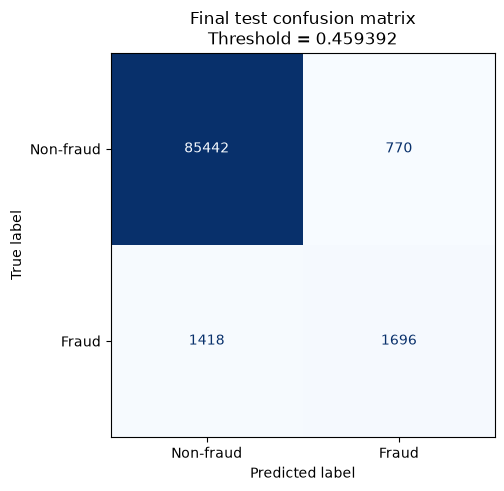

Final bundle reload and threshold predictions verified.
The JSON model alone does not include the encoder or threshold; use final_model_bundle.joblib for the complete prediction pipeline.


In [4]:
predicted = (selected_scores > threshold).astype(np.int8)
matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.6, 4.8), constrained_layout=True)
ConfusionMatrixDisplay(matrix, display_labels=['Non-fraud', 'Fraud']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Final test confusion matrix\nThreshold = {threshold:.6f}')
fig.savefig(OUTPUT_DIR / 'test_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

pd.DataFrame({'TransactionID': test_ids, 'isFraud': y_test,
              'baseline_score': baseline_scores, 'selected_score': selected_scores,
              'final_prediction': predicted}).to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

evaluation = {'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
    'manifest': manifest, 'test_performance_evaluated': True,
    'threshold_selection': selection, 'selected_hyperparameters': tuning_run['selection']['parameters'],
    'test_metrics': results, 'validation_final_metrics': validation_metrics,
    'test_used_for_selection': False, 'model_refit_for_test': False,
    'limitation': 'Outer split boundaries were label-informed in the upstream project. Evaluation retains the original split policy.'}
save_json(OUTPUT_DIR / 'final_test_results.json', evaluation)

export_bundle = dict(final_bundle)
export_bundle['metadata'] = copy.deepcopy(final_bundle['metadata'])
export_bundle['metadata'].update(test_performance_evaluated=True, final_test_evaluation=evaluation)
joblib.dump(export_bundle, OUTPUT_DIR / 'final_model_bundle.joblib', compress=3)
export_bundle['model'].save_model(OUTPUT_DIR / 'final_xgboost.json')
save_json(OUTPUT_DIR / 'final_config.json', {
    'model': 'XGBoost', 'candidate_id': CANDIDATE_ID, 'threshold': threshold, 'threshold_rule': '>',
    'threshold_objective': selection['objective'], 'training_sampling_ratio': 0.1,
    'selected_hyperparameters': tuning_run['selection']['parameters'],
    'constructor_parameters': export_bundle['model'].get_params(),
    'features': export_bundle['features'], 'categorical_columns': export_bundle['categorical_columns'],
    'versions': versions, 'input_contract': 'Already-engineered features from the original project pipeline'})

def predict_with_bundle(frame, fitted_bundle):
    assert fitted_bundle['threshold_rule'] == '>'
    score = predict_scores(frame, fitted_bundle)
    return score, (score > float(fitted_bundle['threshold'])).astype(np.int8)

reloaded = joblib.load(OUTPUT_DIR / 'final_model_bundle.joblib')
probe_scores, probe_predictions = predict_with_bundle(probe_raw, reloaded)
np.testing.assert_array_equal(probe_scores, selected_scores[:len(probe_raw)])
np.testing.assert_array_equal(probe_predictions, predicted[:len(probe_raw)])
print('Final bundle reload and threshold predictions verified.')
print('The JSON model alone does not include the encoder or threshold; use final_model_bundle.joblib for the complete prediction pipeline.')

## 5. Results summary

Generate a factual summary of the method, selected parameters, threshold, measured results and evaluation limitation. The summary does not claim statistical significance, calibrated probabilities or deployment readiness.


In [5]:
baseline_test = results['Step 1 baseline at 0.5']
tuned_default = results['Step 2 tuned model at 0.5']
report = f"""Fraud model tuning and final evaluation

Model selection: XGBoost candidate {CANDIDATE_ID}, selected using mean average precision over three chronological folds within the training period. Random undersampling remained 0.1. Fold-specific frequency encodings and delayed historical fraud features were rebuilt using the permitted training history.

Selected hyperparameters: {json.dumps(tuning_run['selection']['parameters'], sort_keys=True)}

Threshold selection: maximized validation F1 using score > {threshold!r}. Validation precision was {validation_metrics['precision']:.4f}, recall {validation_metrics['recall']:.4f}, F1 {validation_metrics['f1']:.4f} and average precision {validation_metrics['average_precision']:.4f}. These are threshold-selection results.

Final test evaluation: {final_metrics['rows']:,} transactions, including {final_metrics['fraud_count']:,} fraud cases. With the fixed model and threshold, precision was {final_metrics['precision']:.4f}, recall {final_metrics['recall']:.4f}, F1 {final_metrics['f1']:.4f}, average precision {final_metrics['average_precision']:.4f} and ROC AUC {final_metrics['roc_auc']:.4f}.

The final system flagged {final_metrics['alerts']:,} transactions, including {final_metrics['tp']:,} fraud cases and {final_metrics['fp']:,} false alarms. It missed {final_metrics['fn']:,} fraud cases.

Comparison on the same test split: the original baseline at 0.5 had F1 {baseline_test['f1']:.4f} and AP {baseline_test['average_precision']:.4f}; the hyperparameter-tuned model at 0.5 had F1 {tuned_default['f1']:.4f} and AP {tuned_default['average_precision']:.4f}. Threshold tuning leaves the tuned model's AP unchanged.

The model and threshold were fixed before this test evaluation. No retraining, hyperparameter search or threshold optimization used the test outcomes. The original preprocessing chose split boundaries with knowledge of fraud rates across periods, including test; the reported results retain that evaluation limitation. The saved model bundle expects already-engineered features and does not include upstream raw-data feature engineering.
"""
(OUTPUT_DIR / 'results_summary.txt').write_text(report, encoding='utf-8')
print(report)

Fraud model tuning and final evaluation

Model selection: XGBoost candidate 15, selected using mean average precision over three chronological folds within the training period. Random undersampling remained 0.1. Fold-specific frequency encodings and delayed historical fraud features were rebuilt using the permitted training history.

Selected hyperparameters: {"colsample_bytree": 0.85, "learning_rate": 0.05, "max_depth": 6, "min_child_weight": 3, "n_estimators": 400, "reg_alpha": 0.0, "reg_lambda": 3.0, "subsample": 1.0}

Threshold selection: maximized validation F1 using score > 0.45939168334007263. Validation precision was 0.7543, recall 0.5998, F1 0.6682 and average precision 0.7066. These are threshold-selection results.

Final test evaluation: 89,326 transactions, including 3,114 fraud cases. With the fixed model and threshold, precision was 0.6878, recall 0.5446, F1 0.6079, average precision 0.6263 and ROC AUC 0.9182.

The final system flagged 2,466 transactions, including 1,696 